In [1]:
import random
import numpy as np
import torch
import copy

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## 0 Data
### 0.1 Loading and Preparation

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import os

# Find the zip by searching for wikiart keyword
result = !find /content/drive/MyDrive -maxdepth 2 -name "*.zip" | grep -i "2026"
DRIVE_FOLDER = os.path.dirname(result[0])
print(f"Found zip in: {DRIVE_FOLDER}")

if not os.path.exists("/content/wikiart_hw2.npz"):
    !unzip -q "{DRIVE_FOLDER}/Δεδομένα 2ης Εργασίας 2026.zip" -d /content/
    !unzip -q "/content/Δεδομένα 2ης Εργασίας 2026/wikiart_hw2.npz.zip" -d /content/

data = np.load("/content/wikiart_hw2.npz", allow_pickle=True)

Mounted at /content/drive
Found zip in: /content/drive/MyDrive/Μηχανικη Μαθηση Project2


In [3]:
X_raw = data["X"]
y_raw = data["y"]
class_names = data["class_names"]

print("X shape:", X_raw.shape, X_raw.dtype)
print("y shape:", y_raw.shape, y_raw.dtype)
print("Classes:", class_names)

X shape: (5400, 32, 32, 3) uint8
y shape: (5400,) int64
Classes: ['Baroque' 'Impressionism' 'Cubism' 'Abstract_Expressionism']


In [4]:
import torch

X = torch.tensor(X_raw, dtype=torch.float32) / 255.0
X = X.permute(0, 3, 1, 2)
y = torch.tensor(y_raw, dtype=torch.int64)

print("X tensor:", X.shape, X.dtype)
print("y tensor:", y.shape, y.dtype)

X tensor: torch.Size([5400, 3, 32, 32]) torch.float32
y tensor: torch.Size([5400]) torch.int64


In [5]:
from sklearn.model_selection import train_test_split

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=1400, stratify=y, random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=800, stratify=y_trainval, random_state=42
)

for name, labels in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"\n{name} has total: {len(labels)}")
    for i, class_name in enumerate(class_names):
      print(f"  {class_name}: {(labels == i).sum().item()}")


train has total: 3200
  Baroque: 800
  Impressionism: 800
  Cubism: 800
  Abstract_Expressionism: 800

val has total: 800
  Baroque: 200
  Impressionism: 200
  Cubism: 200
  Abstract_Expressionism: 200

test has total: 1400
  Baroque: 350
  Impressionism: 350
  Cubism: 350
  Abstract_Expressionism: 350


In [6]:
from torch.utils.data import TensorDataset, DataLoader

train_ds = TensorDataset(X_train, y_train)
val_ds = TensorDataset(X_val, y_val)
test_ds = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 200
Val batches: 50
Test batches: 88


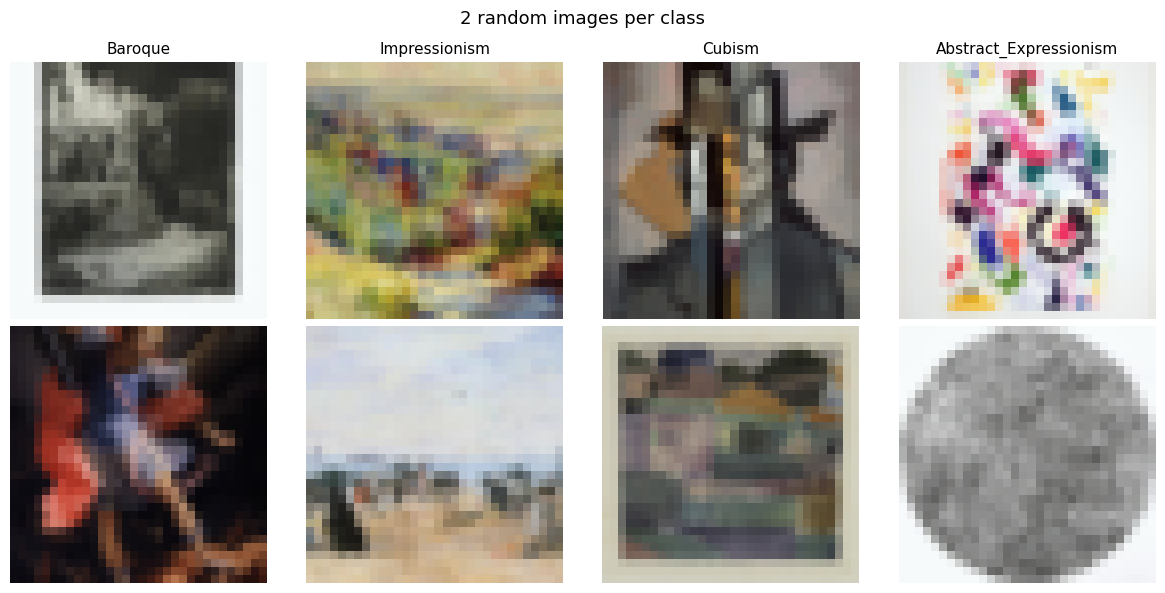

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for col, cls_idx in enumerate(range(4)):
    indices = (y_train == cls_idx).nonzero(as_tuple=True)[0]
    chosen  = indices[torch.randperm(len(indices))[:2]]

    for row in range(2):
        img = X_train[chosen[row]].permute(1, 2, 0).numpy()
        axes[row, col].imshow(img)
        axes[row, col].axis("off")
        if row == 0:
            axes[row, col].set_title(class_names[cls_idx], fontsize=11)

plt.suptitle("2 random images per class", fontsize=13)
plt.tight_layout()
plt.show()

## Sub-question Q0.1
**From the visualization, which visual features seem to differentiate the four movements the most from each other (color palette, texture, composition, presence of subject) ?**
<br><br>
After viewing the above plot the four movements show consistent distinguishing features.

- **Baroque** shows a bimodal tonal distribution some samples are either very dark with dramatic light-dark contrast and realistic human figures and portraits while others have grey/white backgrounds in a sketch style.

- **Impressionism** consistently shows brighter palettes of blues, greens and warm yellows, and outdoor scenes such as landscapes, seascapes, rivers, ports with ships, houses and crowd scenes.

- **Cubism** is easily distinguishable as objects are represented either through geometric shapes or through sharp straight lines and curves. It uses a wide variety of colors with different color intensities, unlike Baroque or Impressionism which tend to follow a specific color tone. Even at 32×32 the geometric structure remains clearly visible.

- **Abstract Expressionism** represents abstract and obscured objects or scenes with no recognizable subject matter. It uses a wide variety of colors with different color intensities, similar to Cubism, unlike Baroque or Impressionism which tend to follow a specific color tone.

<br> <br>

**Which pairs of classes do you expect a classifier to most easily confuse, and why ?**

The most likely confused pair is Cubism and Abstract Expressionism, because both use a wide variety of colors with different color intensities, unlike Baroque and Impressionism which tend to follow a specific color tone. A potential distinguishing factor between these two is that Cubism represents objects through geometric shapes or sharp straight lines and curves, however it is unclear whether a classifier can detect these representations at 32×32 resolution, at such low resolution the geometric structure may be lost and interpreted as abstract and obscured objects or scenes with no recognizable subject matter, similar to Abstract Expressionism.
<br> <br>
In contrast, Baroque and Impressionism are easier to separate because each has very specific and distinct visual characteristics. Baroque shows a bimodal tonal distribution some samples are either very dark with dramatic light-dark contrast and realistic human figures and portraits, or have grey/white backgrounds in a sketch style. Impressionism on the other hand consistently shows brighter palettes of blues, greens and warm yellows with outdoor scenes such as landscapes, seascapes, rivers, ports with ships, houses and crowd scenes. These specific characteristics make this pair easier for a classifier to distinguish even at 32×32.
<br> <br>

**If a human viewed the same images resized to 32×32, which movement would be the most difficult to identify ?**

I think that a human, subjectively speaking, can detect each of the four movements because, as I said in the section above, each one has distinct and separable characteristics and with those can easily be distinguished even at 32×32 resolution.


## 1. Feedforward Neural Network σε raw pixels
### 1.1 Architecture and Training

In [8]:
import torch.nn as nn

# class FFN model
class FFN(nn.Module):

    # Constructor
    def __init__(self):

        # Calls the Constructor of the parent class i.e. nn.Module
        super().__init__()

        # Sequential Container that defines the order of layers to run one after another
        # input -> Flatten -> Linear -> ReLU -> Linear -> ReLU -> Linear -> output
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, 4)
        )

    # One image has shape [3, 32, 32]:
    #   - 3 color channels (R, G, B)
    #   - 32 pixels tall
    #   - 32 pixels wide
    #   - 3 * 32 * 32 = 3072 values when flattened

    # x is a batch of images with shape [batch_size, 3, 32, 32]
    # forward passes x through all layers in self.net and returns the output
    def forward(self, x):
        return self.net(x)

In [9]:
from sklearn.metrics import f1_score, confusion_matrix


# returns mean train loss for the epoch
def train_one_epoch(model, loader, optimizer, criterion, device):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in loader:

      X_batch = X_batch.to(device)
      y_batch = y_batch.to(device)

      optimizer.zero_grad()
      logits = model(X_batch)
      loss = criterion(logits, y_batch)
      loss.backward()
      optimizer.step()

      total_loss += loss.item() * y_batch.size(0)
      total_samples += y_batch.size(0)

    return total_loss / total_samples

def evaluate(model, loader, criterion, device):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            total_loss += loss.item() * y_batch.size(0)
            total_samples += y_batch.size(0)

            preds = logits.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y_batch.cpu().numpy())

    avg_loss = total_loss / total_samples
    acc = np.mean(np.array(all_preds) == np.array(all_labels))
    f1 = f1_score(all_labels, all_preds, average="macro")
    cm = confusion_matrix(all_labels, all_preds)

    return avg_loss, acc, f1, cm

In [10]:
import random

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [11]:
import time
import copy

# Trains the model on the given device (CPU or GPU) for a given number of epochs
def trains_on_device(device_name, epochs, seed=SEED):

    device = torch.device(device_name)

    # Re-seed so both runs (CPU and GPU) start from the same random state.
    # Without re-seeding, the GPU run would start from a different random state
    # than the CPU run, because the CPU run changed the random state.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    model = FFN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    best_f1 = -1.0
    best_state = None
    best_epoch = 0

    train_history = {"train_loss": [], "val_loss": [], "val_f1": []}

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, _, val_f1, _ = evaluate(model, val_loader, criterion, device)

        train_history["train_loss"].append(train_loss)
        train_history["val_loss"].append(val_loss)
        train_history["val_f1"].append(val_f1)

        if val_f1 > best_f1:

            best_f1 = val_f1

            # We found a better val F1, so we save the model weights at this moment.
            # model.state_dict() is a dictionary that contains all the learned weights
            # and biases of the model from all layers.
            # Since training continues and the next epoch will overwrite these weights,
            # we use copy.deepcopy() to take a frozen snapshot of them right now
            # and store it in best_state
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if epoch % 5 == 0:
            print(f"Epoch = {epoch:2d} | train_loss = {train_loss:.4f} | val_loss = {val_loss:.4f} | val_F1 = {val_f1:.4f}")

    end_time = time.time() - start_time
    print(f"\nDevice = {device_name} | Training time: {end_time:.1f}s  |  Best epoch: {best_epoch}  |  Best val F1: {best_f1:.4f}\n\n")

    # Restore best model weights before returning
    model.load_state_dict(best_state)

    return model, train_history, best_epoch

In [12]:
print(f"FFN parameters: {sum(p.numel() for p in FFN().parameters())}")

print("=" * 55)
print("Training on CPU")
print("=" * 55)
ffn_cpu, train_history_cpu, best_epoch_cpu = trains_on_device("cpu",  epochs=30)

print("=" * 55)
print("Training on GPU")
print("=" * 55)
ffn_gpu, train_history_gpu, best_epoch_gpu = trains_on_device("cuda", epochs=30)

FFN parameters: 397604
Training on CPU
Epoch =  5 | train_loss = 1.2297 | val_loss = 1.2484 | val_F1 = 0.3926
Epoch = 10 | train_loss = 1.1476 | val_loss = 1.1994 | val_F1 = 0.4259
Epoch = 15 | train_loss = 1.0842 | val_loss = 1.1837 | val_F1 = 0.4646
Epoch = 20 | train_loss = 1.0408 | val_loss = 1.1974 | val_F1 = 0.4488
Epoch = 25 | train_loss = 0.9775 | val_loss = 1.1957 | val_F1 = 0.4852
Epoch = 30 | train_loss = 0.9339 | val_loss = 1.1776 | val_F1 = 0.4983

Device = cpu | Training time: 52.7s  |  Best epoch: 26  |  Best val F1: 0.5026


Training on GPU
Epoch =  5 | train_loss = 1.2297 | val_loss = 1.2484 | val_F1 = 0.3926
Epoch = 10 | train_loss = 1.1476 | val_loss = 1.1994 | val_F1 = 0.4259
Epoch = 15 | train_loss = 1.0842 | val_loss = 1.1837 | val_F1 = 0.4646
Epoch = 20 | train_loss = 1.0345 | val_loss = 1.2311 | val_F1 = 0.4321
Epoch = 25 | train_loss = 0.9785 | val_loss = 1.1810 | val_F1 = 0.4826
Epoch = 30 | train_loss = 0.9309 | val_loss = 1.1811 | val_F1 = 0.4897

Device = c

In [13]:
# Pick the best model based on val F1
if train_history_gpu["val_f1"][best_epoch_gpu - 1] >= train_history_cpu["val_f1"][best_epoch_cpu - 1]:
    best_model = ffn_gpu
    best_history = train_history_gpu
    best_epoch = best_epoch_gpu
    best_device = torch.device("cuda")
    print(f"Best device = GPU  with:  Best epoch = {best_epoch}  |  Best val F1 = {train_history_gpu['val_f1'][best_epoch_gpu - 1]:.4f}")

else:
    best_model = ffn_cpu
    best_history = train_history_cpu
    best_epoch = best_epoch_cpu
    best_device = torch.device("cpu")
    print(f"Best device = CPU  with:  Best epoch = {best_epoch}  |  Best val F1 = {train_history_cpu['val_f1'][best_epoch_cpu - 1]:.4f}")

Best device = GPU  with:  Best epoch = 26  |  Best val F1 = 0.5029


In [14]:
# Evaluate best model on test set
criterion = nn.CrossEntropyLoss()
test_loss, test_acc, test_f1, test_cm = evaluate(best_model, test_loader, criterion, best_device)
print(f"TEST RESULTS: loss = {test_loss:.4f}  acc = {test_acc:.4f}  F1 = {test_f1:.4f}")

TEST RESULTS: loss = 1.1694  acc = 0.5057  F1 = 0.5044


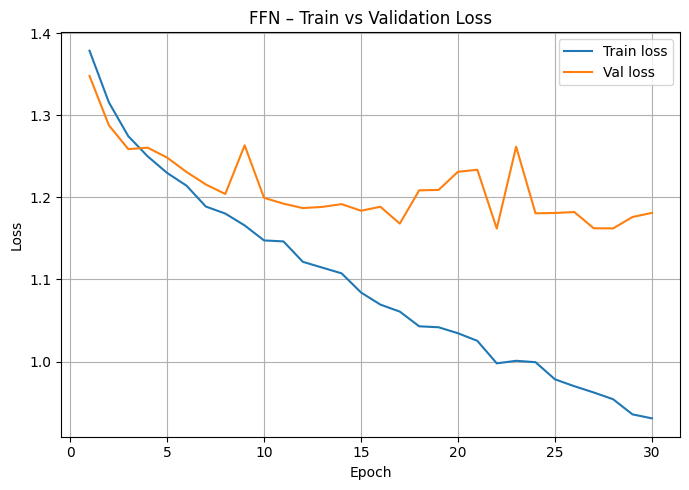

In [15]:
epochs_range = range(1, 31)

# Plot (a): train vs val loss on the same plot
plt.figure(figsize=(7, 5))
plt.plot(epochs_range, best_history["train_loss"], label="Train loss")
plt.plot(epochs_range, best_history["val_loss"], label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("FFN – Train vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

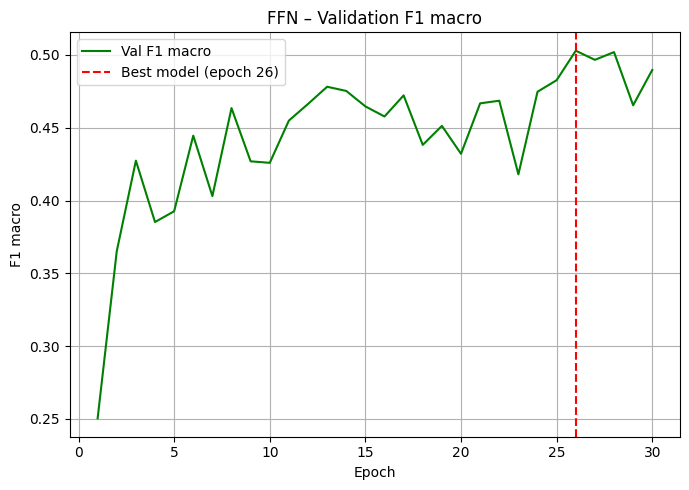

In [16]:
# Plot (b): val F1 with best model marker
plt.figure(figsize=(7, 5))
plt.plot(epochs_range, best_history["val_f1"], label="Val F1 macro", color="green")
plt.axvline(x=best_epoch, color="red", linestyle="--", label=f"Best model (epoch {best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("F1 macro")
plt.title("FFN – Validation F1 macro")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Sub-question Q1.1

**Based on the loss curves and the validation F1 curve, do you observe overfitting, underfitting, or balance ?**

Overfitting is clearly observed. Train loss decreases continuously across all 30 epochs, while val loss decreases rapidly in the first 5 epochs, then bounces around 1.17 - 1.22 for the remaining epochs, with noticeable spikes at epochs ~9 and ~23. The growing gap between the two curves indicates that the model is increasingly memorizing the training data without generalizing effectively to unseen data.
<br> <br>
**At which epoch was the best model selected using the validation F1 criterion, and at which epoch would it have been selected if you had used the train loss as the criterion ?**

Using the validation F1 criterion, the best model was selected at epoch 26 (val F1 = 0.5029). If train loss had been used as the criterion instead, the best model would have been selected at epoch 30, since train loss decreases monotonically throughout all 30 epochs and reaches its minimum of 0.9309 at the last epoch.
<br> <br>
**Why is selection based on the validation set critical ?**

If we had used train loss as the criterion we would have selected epoch 30, but at epoch 30 the val F1 is only 0.4897, lower than the 0.5029 achieved at epoch 26. The model at epoch 30 has overfit more to the training data, and its weights are less generalizable. Without validation based selection we would have deployed a worse model, mistakenly believing that a lower train loss means better performance. The validation based selection finds the checkpoint that best balances training fit and generalization to unseen data, which is what matters.
<br> <br>

**Was the GPU speedup expected compared to CPU training for a network of this size ?**

The GPU speedup was not expected to be significant for a network this small. The FFN has only 3072 -> 128 -> 32 -> 4 neurons per layer (~400K total parameters), which is far too small to saturate GPU parallelism. Despite this, results show CPU took
54.6s vs GPU 15.3s, a ~3.6× speedup. This is somewhat larger than expected for such a tiny model, and is likely due to Colab T4 GPU being efficient even at small scales. For truly tiny networks the GPU overhead can sometimes make it slower.



## Sub-question Q1.2

**Present the accuracy, F1 macro, and confusion matrix of the best model on the test set. Which movements are confused the most with each other ?**

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

def plot_confusion_matrix(cm, title):
    fig, ax = plt.subplots(figsize=(8, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap="viridis", colorbar=True)
    ax.grid(False)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=15)
    ax.set_xlabel("Predicted Label", fontsize=11)
    ax.set_ylabel("True Label", fontsize=11)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()
    print(cm)

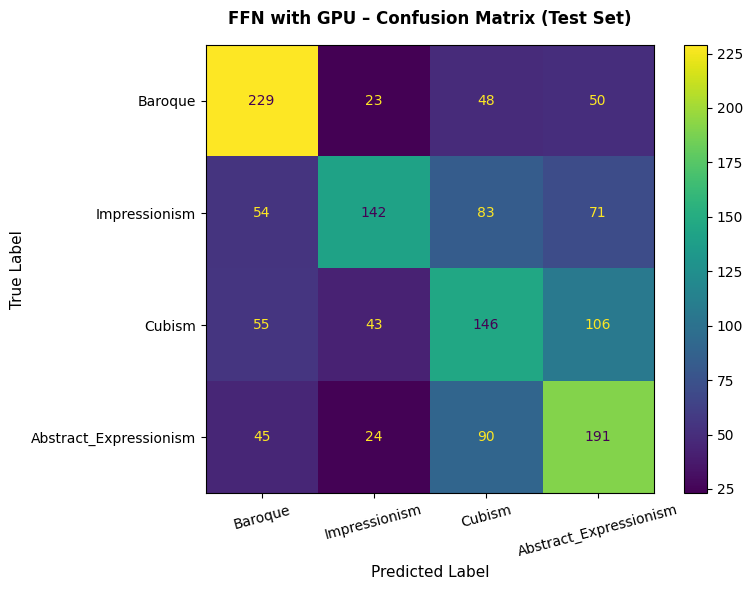

[[229  23  48  50]
 [ 54 142  83  71]
 [ 55  43 146 106]
 [ 45  24  90 191]]


In [18]:
plot_confusion_matrix(test_cm, "FFN with GPU – Confusion Matrix (Test Set)")

The best model achieves test accuracy = 0.5057 and F1 macro = 0.5044. From the confusion matrix, the most confused pair is Cubism and Abstract Expressionism, 106 Cubism samples are misclassified as Abstract Expressionism and 90 Abstract Expressionism samples are misclassified as Cubism. This confirms the prediction made in Q0.1 that these two classes would be the hardest to separate. Baroque is the best recognized class (229/350 correct), while Impressionism is the weakest (142/350 correct), being confused with both Cubism (83) and Abstract Expressionism (71).

Weights shape: torch.Size([128, 3072])
Reshaped: torch.Size([128, 3, 32, 32])


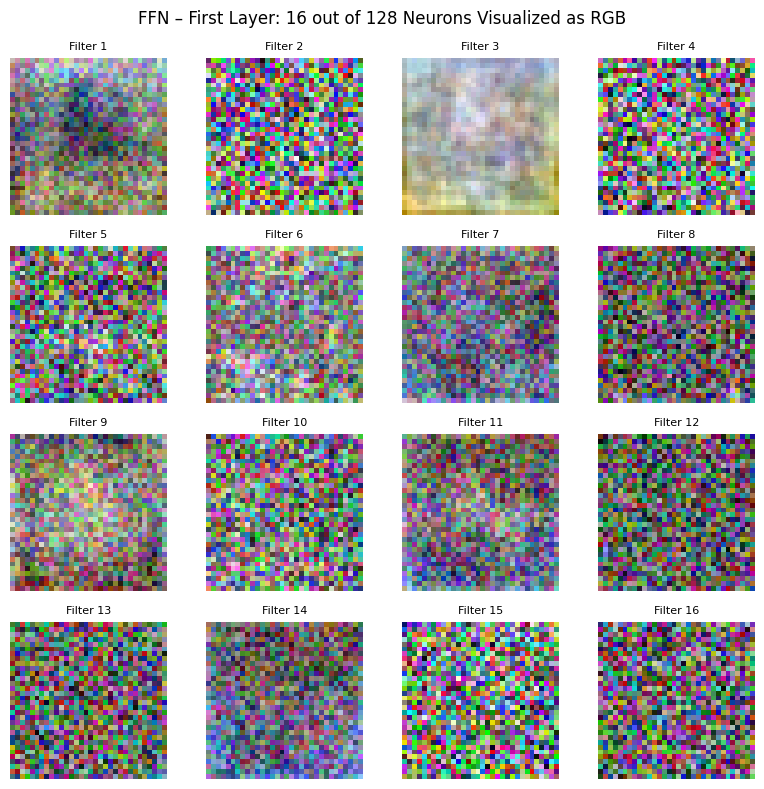

In [19]:
# Our FFN self.net is a nn.Sequential with these layers in order:

# net[0] = nn.Flatten()
# net[1] = nn.Linear(3072, 128)
# net[2] = nn.ReLU()
# net[3] = nn.Linear(128, 32)
# net[4] = nn.ReLU()
# net[5] = nn.Linear(32, 4)
weights = best_model.net[1].weight.data.cpu()

# .weight.data retrieves the weights of the layer as they are being stored
# PyTorch stores nn.Linear(3072, 128) weights as [out_features, in_features] = [128, 3072]
# meaning:
# 128 = number of neurons in that layer (out_features)
# 3072 = number of inputs, one weight per input pixel (in_features)

# So each of the 128 neurons has 3072 weights, one for each pixel of the flattened image

print("Weights shape:", weights.shape)

# Reshape to [128, 3, 32, 32]
weights_reshaped = weights.reshape(128, 3, 32, 32)
print("Reshaped:", weights_reshaped.shape)

# Normalize each filter to [0, 1] using min-max per filter
# the filter f corresponds to one neuron, reshaped from [3072] (flat) to [3, 32, 32] (image)
# so we can visualize it as an RGB image
filters_normalized = []
for i in range(128):
    f = weights_reshaped[i]
    f_min = f.min()
    f_max = f.max()
    f_norm = (f - f_min) / (f_max - f_min + 1e-8)
    filters_normalized.append(f_norm)

# Visualize first 16 filters as RGB images
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    img = filters_normalized[i].permute(1, 2, 0).numpy()
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"Filter {i+1}", fontsize=8)

plt.suptitle("FFN – First Layer: 16 out of 128 Neurons Visualized as RGB", fontsize=12)
plt.tight_layout()
plt.show()

**Discuss why the flat-pixel FFN struggles despite having ReLU: what does each neuron in the first layer 'see', and what kind of image structure can this architecture not exploit ?**

Each neuron in the first layer of the FFN computes a weighted sum over all
3072 pixel values simultaneously one weight per pixel per color channel:

```
output = (w_r1 * red_pixel1) + (w_g1 * green_pixel1) + (w_b1 * blue_pixel1) +
         (w_r2 * red_pixel2) + (w_g2 * green_pixel2) + (w_b2 * blue_pixel2)     +
         ...
         (w_r1024 * red_pixel1024) + (w_g1024 * green_pixel1024) + (w_b1024 * blue_pixel1024)
```

This means each neuron produces one single number as output, and "sees"
the entire image as a flat list of 3072 independent numbers, with no notion of which pixels are spatially close to each other.

The architecture cannot exploit local spatial structure such as edges,
textures, corners or shapes because flattening destroys all spatial
relationships e.g. pixel(0,0) and pixel(0,1) are neighbors in the image
but become just two unrelated positions in the flat list.

ReLU adds non-linearity by zeroing out negative activations, but it
does not introduce any spatial awareness, it is simply applied to a sum computed from all pixels across the entire image. This is confirmed by the visualization i.e. all 16 filters appear as random noise with no recognizable spatial patterns, meaning the neurons failed to learn meaningful local features.

## 2. Convolutional Neural Network
### 2.1 Gradual Construction

###**§2.1 baseline**

In [20]:
class cnn_baseline(nn.Module):

    # Constructor
    def __init__(self):

        # Calls the Constructor of the parent class i.e. nn.Module
        super().__init__()

        # each Conv2d represents one stage of feature extraction from the image
        # according to the assignment we have 4 stages + the original image (32 * 32 * 3, where 3 = RGB)
        # in each stage because we have kernel = 5 and no padding the image shrinks by 4:
        # formula: output = input - kernel + 2 * padding + 1 = input - 5 + 1 = input - 4
        #
        #   original image:  32 * 32 *   3  (3 RGB channels)
        #   after conv1:     28 * 28 *  16  (image shrinks, but we gain 16 feature maps)
        #   after conv2:     24 * 24 *  32  (image shrinks, but we gain 32 feature maps)
        #   after conv3:     20 * 20 *  64  (image shrinks, but we gain 64 feature maps)
        #   after conv4:     16 * 16 * 128  (image shrinks, but we gain 128 feature maps)
        #
        # so in the last stage we went from 3 simple RGB values to 128 feature representations
        # each feature map captures more meaningful information about the painting style

        # So in self.features we extract features
        # filter = the 5 * 5 sliding window that slides across the image (the tool)
        # feature = the output of applying a filter to the image (the result)

        self.features = nn.Sequential(
            nn.Conv2d(3 , 16, kernel_size=5),
            nn.Conv2d(16, 32, kernel_size=5),
            nn.Conv2d(32, 64, kernel_size=5),
            nn.Conv2d(64, 128,kernel_size=5),
        )

        # x is the flattened output of the last conv stage: 16 * 16 (image size) * 128 (feature maps)
        x = 128 * 16 * 16

        # classifier: at each step we downgrade to a smaller rank combining the features
        # until we are left with 4 scores one for each art style
        #   0 -> Baroque
        #   1 -> Impressionism
        #   2 -> Cubism
        #   3 -> Abstract Expressionism
        # each number in the rank represents one neuron that computes a weighted sum of all inputs
        # nn.Linear(in, out): in = inputs from previous rank, out = neurons in this layer
        # each neuron looks at ALL inputs: output = w1 * input1 + w2 * input2 + ... + wN * inputN
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(x, 1024), # compress x features into 1024
            nn.Linear(1024, 256),
            nn.Linear(256, 32),
            nn.Linear(32, 4), # compress 32 features into 4 (final decision: 4 scores (one per art style))
        )

    # x is a batch of images with shape [batch_size, 3, 32, 32]
    # forward passes x through:
    #   1. self.features   (conv layers)   -> extracts features from the image
    #   2. self.classifier (linear layers) -> downgrades features to 4 class scores (Baroque, Impressionism, Cubism, Abstract Expressionism)
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

###**§2.2 cnn with padding and pooling**

In [21]:
class cnn_pad_pool(nn.Module):

    # Constructor
    def __init__(self):

        # Calls the Constructor of the parent class i.e. nn.Module
        super().__init__()

        # padding = 2 adds 2 pixels of zeros around the border of the image
        # this preserves the edge pixels that were lost in the cnn_baseline class when the
        # 5 * 5 filter could not be centered on them

        # MaxPool2d(kernel_size=2) takes every 2x2 block of pixels
        # and keeps only the maximum value, discarding the other 3
        # this halves the spatial size after each conv

        # formula with padding: output = input - kernel + 2 * padding + 1 = input (which means we have output = input i.e. size is preserved)
        # MaxPool2d(kernel_size=2) takes every 2 * 2 block and keeps only the maximum value
        # formula for MaxPool: output = input / 2
        #
        #   original image: 32 * 32 * 3  (3 RGB channels)
        #   after conv1: 32 * 32 * 16  (with padding = 2 preserves size, we gain 16 feature maps)
        #   after pool1: 16 * 16 * 16  (MaxPool halves the size)
        #   after conv2: 16 * 16 * 32  (with padding = 2 preserves size, we gain 32 feature maps)
        #   after pool2: 8 *  8 *  32  (MaxPool halves the size)
        #   after conv3: 8 *  8 *  64  (with padding = 2 preserves size, we gain 64 feature maps)
        #   after pool3: 4 *  4 *  64  (MaxPool halves the size)
        #   after conv4: 4 *  4 * 128  (with padding = 2 preserves size, we gain 128 feature maps)
        #   after pool4: 2 *  2 * 128  (MaxPool halves the size)

        # So in self.features we extract features
        # filter = the 5 * 5 sliding window that slides across the image (the tool)
        # feature = the output of applying a filter to the image (the result)

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64,  128, kernel_size=5, padding=2),
            nn.MaxPool2d(kernel_size=2),
        )

        # x is the flattened output of the last stage: 2 * 2 (image size) * 128 (feature maps)
        x = 128 * 2 * 2

        # classifier: same structure as in cnn_baseline class
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(x, 1024),
            nn.Linear(1024, 256),
            nn.Linear(256, 32),
            nn.Linear(32, 4),
        )

    # x is a batch of images with shape [batch_size, 3, 32, 32]
    # forward passes x through:
    #   1. self.features   (conv layers)   -> extracts features from the image
    #   2. self.classifier (linear layers) -> downgrades features to 4 class scores (Baroque, Impressionism, Cubism, Abstract Expressionism)
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

###**§2.2 cnn with padding, pooling and ReLU**

In [22]:
class cnn_pad_pool_relu(nn.Module):

    # Constructor
    def __init__(self):

        # Calls the Constructor of the parent class i.e. nn.Module
        super().__init__()

        # The cnn_pad_pool class but with additional ReLU is added after each conv (before pooling)
        # ReLU sets all negative values to 0: output = max(0, input)
        # this introduces non-linearity so the network can learn complex patterns
        # without ReLU all conv layers collapse into one linear operation

        #   original image: 32 * 32 * 3  (3 RGB channels)
        #   after conv1: 32 * 32 * 16  (with padding = 2 preserves size, we gain 16 feature maps)
        #   after relu1: 32 * 32 * 16  (ReLU does not change size, only zeroes negatives)
        #   after pool1: 16 * 16 * 16  (MaxPool halves the size)
        #   after conv2: 16 * 16 * 32  (with padding = 2 preserves size, we gain 32 feature maps)
        #   after relu2: 16 * 16 * 32  (ReLU does not change size, only zeroes negatives)
        #   after pool2: 8 *  8 *  32  (MaxPool halves the size)
        #   after conv3: 8 *  8 *  64  (with padding = 2 preserves size, we gain 64 feature maps)
        #   after relu3: 8 *  8 *  64  (ReLU does not change size, only zeroes negatives)
        #   after pool3: 4 *  4 *  64  (MaxPool halves the size)
        #   after conv4: 4 *  4 * 128  (with padding = 2 preserves size, we gain 128 feature maps)
        #   after relu4: 4 *  4 * 128  (ReLU does not change size, only zeroes negatives)
        #   after pool4: 2 *  2 * 128  (MaxPool halves the size)

        # So in self.features we extract features
        # filter = the 5 * 5 sliding window that slides across the image (the tool)
        # feature = the output of applying a filter to the image (the result)

        self.features = nn.Sequential(
            nn.Conv2d(3, 16,  kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32,  kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64,  kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        # x is the flattened output of the last stage: 2 * 2 (image size) * 128 (feature maps)
        x = 128 * 2 * 2

        # classifier: same structure as in cnn_pad_pool class but with additional
        # ReLU added before each Linear except the last one
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.ReLU(),
            nn.Linear(x, 1024),
            nn.ReLU(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Linear(32, 4),
        )

    # x is a batch of images with shape [batch_size, 3, 32, 32]
    # forward passes x through:
    #   1. self.features   (conv layers)   -> extracts features from the image
    #   2. self.classifier (linear layers) -> downgrades features to 4 class scores (Baroque, Impressionism, Cubism, Abstract Expressionism)
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [23]:
# Trains a cnn model on the given device (CPU or GPU) for a given number of epochs
# model_class: the class of the model to train i.e. cnn_baseline, cnn_pad_pool, cnn_pad_pool_relu
def train_cnn_on_device(model_class, device_name, epochs=30, seed=SEED):

    device = torch.device(device_name)

    # Re-seed so both runs (CPU and GPU) start from the same random state.
    # Without re-seeding, the GPU run would start from a different random state
    # than the CPU run, because the CPU run changed the random state.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    model = model_class().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    best_f1 = -1.0
    best_state = None
    best_epoch = 0

    train_history = {"train_loss": [], "val_loss": [], "val_f1": []}

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, _, val_f1, _ = evaluate(model, val_loader, criterion, device)

        train_history["train_loss"].append(train_loss)
        train_history["val_loss"].append(val_loss)
        train_history["val_f1"].append(val_f1)

        if val_f1 > best_f1:

            best_f1 = val_f1

            # We found a better val F1, so we save the model weights at this moment.
            # model.state_dict() is a dictionary that contains all the learned weights
            # and biases of the model from all layers.
            # Since training continues and the next epoch will overwrite these weights,
            # we use copy.deepcopy() to take a frozen snapshot of them right now
            # and store it in best_state
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if epoch % 5 == 0:
            print(f"Epoch = {epoch:2d} | train_loss = {train_loss:.4f} | val_loss = {val_loss:.4f} | val_F1 = {val_f1:.4f}")

    end_time = time.time() - start_time
    print(f"\nDevice = {device_name} | Training time: {end_time:.1f}s  |  Best epoch: {best_epoch}  |  Best val F1: {best_f1:.4f}\n\n")

    # Restore best model weights before returning
    model.load_state_dict(best_state)

    return model, train_history, best_epoch, end_time

In [24]:
print("=" * 55)
print("baseline cnn (no padding, no pooling, no activations) on GPU")
print(f"Parameters: {sum(p.numel() for p in cnn_baseline().parameters())}")
print("=" * 55)
model_cnn_baseline_gpu, history_cnn_baseline_gpu, best_epoch_cnn_baseline_gpu, time_cnn_baseline_gpu = train_cnn_on_device(cnn_baseline, "cuda", epochs=30)

baseline cnn (no padding, no pooling, no activations) on GPU
Parameters: 34096452
Epoch =  5 | train_loss = 1.3157 | val_loss = 1.3414 | val_F1 = 0.4077
Epoch = 10 | train_loss = 1.2565 | val_loss = 1.3921 | val_F1 = 0.3475
Epoch = 15 | train_loss = 1.2115 | val_loss = 1.4032 | val_F1 = 0.3496
Epoch = 20 | train_loss = 1.1512 | val_loss = 1.5935 | val_F1 = 0.2433
Epoch = 25 | train_loss = 1.0795 | val_loss = 1.6659 | val_F1 = 0.2864
Epoch = 30 | train_loss = 1.0376 | val_loss = 1.6541 | val_F1 = 0.3629

Device = cuda | Training time: 99.7s  |  Best epoch: 5  |  Best val F1: 0.4077




In [25]:
print("=" * 55)
print("baseline cnn (no padding, no pooling, no activations) on CPU")
print("=" * 55)
model_cnn_baseline_cpu, history_cnn_baseline_cpu, best_epoch_cnn_baseline_cpu, time_cnn_baseline_cpu = train_cnn_on_device(cnn_baseline, "cpu", epochs=30)

baseline cnn (no padding, no pooling, no activations) on CPU
Epoch =  5 | train_loss = 1.3053 | val_loss = 1.3285 | val_F1 = 0.3998
Epoch = 10 | train_loss = 1.2569 | val_loss = 1.3814 | val_F1 = 0.3410
Epoch = 15 | train_loss = 1.2077 | val_loss = 1.4022 | val_F1 = 0.3263
Epoch = 20 | train_loss = 1.1575 | val_loss = 1.6050 | val_F1 = 0.2829
Epoch = 25 | train_loss = 1.0683 | val_loss = 1.6591 | val_F1 = 0.3083
Epoch = 30 | train_loss = 1.0071 | val_loss = 1.7313 | val_F1 = 0.3373

Device = cpu | Training time: 3369.9s  |  Best epoch: 8  |  Best val F1: 0.4001




In [26]:
print("=" * 55)
print("cnn with padding and pooling on GPU")
print(f"Parameters: {sum(p.numel() for p in cnn_pad_pool().parameters())}")
print("=" * 55)
model_cnn_pad_pool_gpu, history_cnn_pad_pool_gpu, best_epoch_cnn_pad_pool_gpu, time_cnn_pad_pool_gpu = train_cnn_on_device(cnn_pad_pool, "cuda", epochs=30)

cnn with padding and pooling on GPU
Parameters: 1066308
Epoch =  5 | train_loss = 0.8747 | val_loss = 1.0352 | val_F1 = 0.5857
Epoch = 10 | train_loss = 0.2332 | val_loss = 1.5066 | val_F1 = 0.5775
Epoch = 15 | train_loss = 0.2453 | val_loss = 1.8233 | val_F1 = 0.5732
Epoch = 20 | train_loss = 0.0650 | val_loss = 2.6065 | val_F1 = 0.5612
Epoch = 25 | train_loss = 0.1445 | val_loss = 3.0147 | val_F1 = 0.5515
Epoch = 30 | train_loss = 0.0003 | val_loss = 3.4182 | val_F1 = 0.5928

Device = cuda | Training time: 23.1s  |  Best epoch: 30  |  Best val F1: 0.5928




In [27]:
print("=" * 55)
print("cnn with padding and pooling on CPU")
print("=" * 55)
model_cnn_pad_pool_cpu, history_cnn_pad_pool_cpu, best_epoch_cnn_pad_pool_cpu, time_cnn_pad_pool_cpu = train_cnn_on_device(cnn_pad_pool, "cpu", epochs=30)

cnn with padding and pooling on CPU
Epoch =  5 | train_loss = 0.9308 | val_loss = 1.0713 | val_F1 = 0.5438
Epoch = 10 | train_loss = 0.2551 | val_loss = 1.7241 | val_F1 = 0.5672
Epoch = 15 | train_loss = 0.1181 | val_loss = 2.1954 | val_F1 = 0.5820
Epoch = 20 | train_loss = 0.0388 | val_loss = 2.8716 | val_F1 = 0.5627
Epoch = 25 | train_loss = 0.0444 | val_loss = 4.1965 | val_F1 = 0.5503
Epoch = 30 | train_loss = 0.0215 | val_loss = 3.2809 | val_F1 = 0.5799

Device = cpu | Training time: 174.0s  |  Best epoch: 6  |  Best val F1: 0.6101




In [28]:
print("=" * 55)
print("cnn with padding, pooling and ReLU on GPU")
print(f"Parameters: {sum(p.numel() for p in cnn_pad_pool_relu().parameters())}")
print("=" * 55)
model_cnn_pad_pool_relu_gpu, history_cnn_pad_pool_relu_gpu, best_epoch_cnn_pad_pool_relu_gpu, time_cnn_pad_pool_relu_gpu = train_cnn_on_device(cnn_pad_pool_relu, "cuda", epochs=30)


cnn with padding, pooling and ReLU on GPU
Parameters: 1066308
Epoch =  5 | train_loss = 1.1953 | val_loss = 1.2595 | val_F1 = 0.3566
Epoch = 10 | train_loss = 0.9844 | val_loss = 1.1500 | val_F1 = 0.4068
Epoch = 15 | train_loss = 0.7013 | val_loss = 1.1335 | val_F1 = 0.5446
Epoch = 20 | train_loss = 0.3389 | val_loss = 1.6580 | val_F1 = 0.5814
Epoch = 25 | train_loss = 0.1645 | val_loss = 2.2109 | val_F1 = 0.5493
Epoch = 30 | train_loss = 0.1129 | val_loss = 2.4957 | val_F1 = 0.5666

Device = cuda | Training time: 25.5s  |  Best epoch: 22  |  Best val F1: 0.5863




In [29]:
print("=" * 55)
print("cnn with padding, pooling and ReLU on CPU")
print("=" * 55)
model_cnn_pad_pool_relu_cpu, history_cnn_pad_pool_relu_cpu, best_epoch_cnn_pad_pool_relu_cpu, time_cnn_pad_pool_relu_cpu = train_cnn_on_device(cnn_pad_pool_relu, "cpu", epochs=30)

cnn with padding, pooling and ReLU on CPU
Epoch =  5 | train_loss = 1.1544 | val_loss = 1.1341 | val_F1 = 0.4574
Epoch = 10 | train_loss = 0.8685 | val_loss = 1.0347 | val_F1 = 0.5519
Epoch = 15 | train_loss = 0.5487 | val_loss = 1.1125 | val_F1 = 0.6011
Epoch = 20 | train_loss = 0.3252 | val_loss = 1.7268 | val_F1 = 0.6086
Epoch = 25 | train_loss = 0.1573 | val_loss = 1.6704 | val_F1 = 0.5985
Epoch = 30 | train_loss = 0.1205 | val_loss = 2.0210 | val_F1 = 0.5962

Device = cpu | Training time: 242.6s  |  Best epoch: 14  |  Best val F1: 0.6167




In [30]:
criterion = nn.CrossEntropyLoss()

# baseline cnn (no padding, no pooling, no activations) on GPU
_, val_acc_baseline_gpu,  val_f1_baseline_gpu,  _ = evaluate(model_cnn_baseline_gpu, val_loader,  criterion, torch.device("cuda"))
_, test_acc_baseline_gpu, test_f1_baseline_gpu, _ = evaluate(model_cnn_baseline_gpu, test_loader, criterion, torch.device("cuda"))

# baseline cnn (no padding, no pooling, no activations) on CPU
_, val_acc_baseline_cpu,  val_f1_baseline_cpu,  _ = evaluate(model_cnn_baseline_cpu, val_loader,  criterion, torch.device("cpu"))
_, test_acc_baseline_cpu, test_f1_baseline_cpu, _ = evaluate(model_cnn_baseline_cpu, test_loader, criterion, torch.device("cpu"))

# cnn with padding and pooling on GPU
_, val_acc_cnn_pad_pool_gpu,  val_f1_cnn_pad_pool_gpu,  _ = evaluate(model_cnn_pad_pool_gpu, val_loader,  criterion, torch.device("cuda"))
_, test_acc_cnn_pad_pool_gpu, test_f1_cnn_pad_pool_gpu, _ = evaluate(model_cnn_pad_pool_gpu, test_loader, criterion, torch.device("cuda"))

# cnn with padding and pooling on CPU
_, val_acc_cnn_pad_pool_cpu,  val_f1_cnn_pad_pool_cpu,  _ = evaluate(model_cnn_pad_pool_cpu, val_loader,  criterion, torch.device("cpu"))
_, test_acc_cnn_pad_pool_cpu, test_f1_cnn_pad_pool_cpu, _ = evaluate(model_cnn_pad_pool_cpu, test_loader, criterion, torch.device("cpu"))

# cnn with padding, pooling and ReLU on GPU
_, val_acc_cnn_pad_pool_relu_gpu,  val_f1_cnn_pad_pool_relu_gpu,  _ = evaluate(model_cnn_pad_pool_relu_gpu, val_loader,  criterion, torch.device("cuda"))
_, test_acc_cnn_pad_pool_relu_gpu, test_f1_cnn_pad_pool_relu_gpu, test_cm_cnn = evaluate(model_cnn_pad_pool_relu_gpu, test_loader, criterion, torch.device("cuda"))

# cnn with padding, pooling and ReLU on CPU
_, val_acc_cnn_pad_pool_relu_cpu,  val_f1_cnn_pad_pool_relu_cpu,  _ = evaluate(model_cnn_pad_pool_relu_cpu, val_loader,  criterion, torch.device("cpu"))
_, test_acc_cnn_pad_pool_relu_cpu, test_f1_cnn_pad_pool_relu_cpu, _ = evaluate(model_cnn_pad_pool_relu_cpu, test_loader, criterion, torch.device("cpu"))

## Sub-question Q2.1

In [31]:
import pandas as pd

rows = []

rows.append({
    'Version'  : '§2.1 (without pad/pool/activ) GPU',
    '# params' : 34096452,
    'Val Acc'  : f"{val_acc_baseline_gpu:.4f}",
    'Test Acc' : f"{test_acc_baseline_gpu:.4f}",
    'F1 macro' : f"{test_f1_baseline_gpu:.4f}",
    'Time (s)' : f"{time_cnn_baseline_gpu:.1f}s",
})

rows.append({
    'Version'  : '§2.1 (without pad/pool/activ) CPU',
    '# params' : 34096452,
    'Val Acc'  : f"{val_acc_baseline_cpu:.4f}",
    'Test Acc' : f"{test_acc_baseline_cpu:.4f}",
    'F1 macro' : f"{test_f1_baseline_cpu:.4f}",
    'Time (s)' : f"{time_cnn_baseline_cpu:.1f}s",
})

rows.append({
    'Version'  : '§2.2 (with pad and pool) GPU',
    '# params' : 1066308,
    'Val Acc'  : f"{val_acc_cnn_pad_pool_gpu:.4f}",
    'Test Acc' : f"{test_acc_cnn_pad_pool_gpu:.4f}",
    'F1 macro' : f"{test_f1_cnn_pad_pool_gpu:.4f}",
    'Time (s)' : f"{time_cnn_pad_pool_gpu:.1f}s",
})

rows.append({
    'Version'  : '§2.2 (with pad and pool) CPU',
    '# params' : 1066308,
    'Val Acc'  : f"{val_acc_cnn_pad_pool_cpu:.4f}",
    'Test Acc' : f"{test_acc_cnn_pad_pool_cpu:.4f}",
    'F1 macro' : f"{test_f1_cnn_pad_pool_cpu:.4f}",
    'Time (s)' : f"{time_cnn_pad_pool_cpu:.1f}s",
})

rows.append({
    'Version'  : '§2.3 (with ReLU) GPU',
    '# params' : 1066308,
    'Val Acc'  : f"{val_acc_cnn_pad_pool_relu_gpu:.4f}",
    'Test Acc' : f"{test_acc_cnn_pad_pool_relu_gpu:.4f}",
    'F1 macro' : f"{test_f1_cnn_pad_pool_relu_gpu:.4f}",
    'Time (s)' : f"{time_cnn_pad_pool_relu_gpu:.1f}s",
})

rows.append({
    'Version'  : '§2.3 (with ReLU) CPU',
    '# params' : 1066308,
    'Val Acc'  : f"{val_acc_cnn_pad_pool_relu_cpu:.4f}",
    'Test Acc' : f"{test_acc_cnn_pad_pool_relu_cpu:.4f}",
    'F1 macro' : f"{test_f1_cnn_pad_pool_relu_cpu:.4f}",
    'Time (s)' : f"{time_cnn_pad_pool_relu_cpu:.1f}s",
})

summary_df = pd.DataFrame(rows)
pd.set_option('display.max_colwidth', None)
display(summary_df.style.set_caption("Q2.1 Summary Table"))

,Version,# params,Val Acc,Test Acc,F1 macro,Time (s)
0,§2.1 (without pad/pool/activ) GPU,34096452,0.4188,0.4164,0.4075,99.7s
1,§2.1 (without pad/pool/activ) CPU,34096452,0.4138,0.3900,0.3823,3369.9s
2,§2.2 (with pad and pool) GPU,1066308,0.5900,0.5979,0.5972,23.1s
3,§2.2 (with pad and pool) CPU,1066308,0.6050,0.5714,0.5733,174.0s
4,§2.3 (with ReLU) GPU,1066308,0.5813,0.5700,0.5718,25.5s
5,§2.3 (with ReLU) CPU,1066308,0.6188,0.5971,0.5925,242.6s


**Which change had the greatest impact on performance and which on the number of parameters ?**

The change with the greatest impact on performance was adding padding and pooling (§2.1 -> §2.2): test F1 macro went from 0.4075 (§2.1 using GPU) to 0.5972 (§2.2 using GPU), an improvement of + 0.19. This is because padding preserves edge information that was lost in §2.1, and pooling reduces
the spatial size which drastically reduces the number of parameters in the FC head (from 33M to 524K), reducing overfitting and allowing the network to train more effectively.Adding ReLU (§2.2 ->§2.3) had a smaller effect: 0.5972 (§2.2 using GPU) -> 0.5718 (§2.3 using GPU) which is actually slightly worse on GPU, and 0.5733 (§2.2 using CPU) -> 0.5925 (§2.3 using CPU) which is slightly better on CPU.
<br>

The change with the greatest impact on number of parameters was also adding padding and pooling: parameters dropped from 34096452 to 1066308 , a reduction of 33 million. This happened because MaxPool2d reduces the spatial map from 16×16 to 2×2, so the flatten output drops from
128×16×16=32,768 to 128×2×2=512. This means the first Linear layer shrinks from 32768×1024=33554432 weights to just 512×1024=524288 weights, which is where almost all the parameter reduction comes from.
<br> <br>

**If §2.1 achieves low or near-random performance, explain technically why this happens, beyond the general observation that activations are missing**

§2.1 achieves a test F1 of 0.4075 which is low but not near random (random chance for 4 classes = 0.25). <br>
The technical reasons beyond missing activations are:

- First, without ReLU all 4 conv layers are linear transformations, and stacking linear transformations always reduces to a single linear transformation: `linear(linear(linear(linear(x)))) = linear(x)`. This means the 4 conv layers learn nothing more than 1 conv layer could, the depth of the network provides no benefit.

- Second, without pooling the flatten output is 128×16×16=32768 , making the first Linear layer have 32768×1024=33554432 parameters that must be learned from only 3200 training images. This leads to severe overfitting, visible in the loss curves where train loss drops to 1.03 while val loss rises to 1.70 at epoch 30.

## Sub-question Q2.2

**Compare the final CNN (§2.3) with the FFN from Question 1 on two metrics: number of parameters and test F1 macro. Does the CNN have more or fewer parameters than the FFN? How different is the performance? Discuss why the number of parameters alone does not predict performance, and what role the structure of the parameters plays (how they are organized and what prior knowledge they encode for images)**

The CNN (§2.3) has more parameters than the FFN: 1066308 vs 397604, roughly 2.7x more. Despite having more parameters, the CNN achieves better performance: FFN (GPU) test F1 = 0.5044 vs §2.3 CNN (GPU) test F1 = 0.5718, an improvement of + 0.0674.

<br>

This shows that the number of parameters alone does not predict performance. The FFN has 397604 parameters where every neuron in the first layer is connected to every pixel of the flattened image (3072 values). This means the FFN has no prior knowledge about the spatial structure of images i.e. it treats pixel (0,0) and pixel (31,31) as completely unrelated inputs.

<br>

The CNN on the other hand takes advantage of the spatial structure of images with filters, each filter is a small 5×5 sliding window (kernel_size=5) that looks at local neighborhoods of pixels, sharing the same weights across all positions. This means the CNN knows that nearby pixels are related (local connectivity) and that a pattern detected in one part of the image is useful everywhere (weight sharing). These two properties make CNN parameters far more useful for images than FFN parameters, the CNN learns meaningful spatial patterns while the FFN treats all pixels as unrelated, which is why parameter count alone does not predict performance.


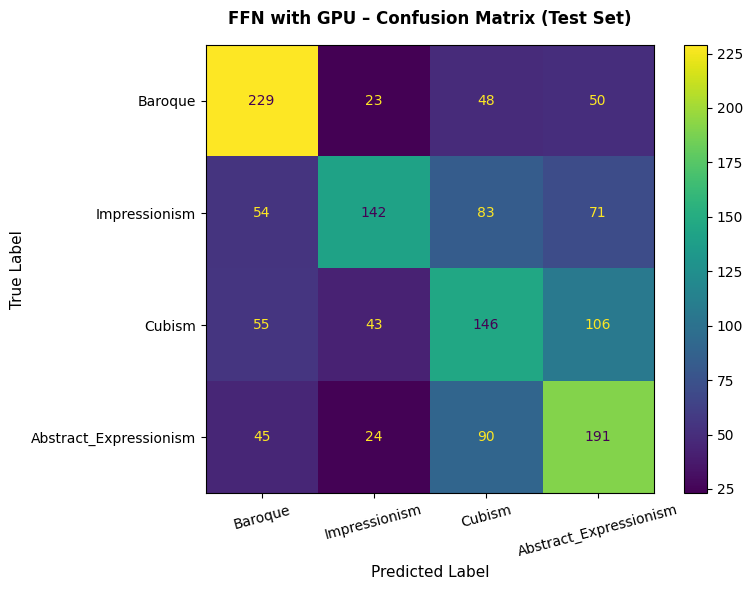

[[229  23  48  50]
 [ 54 142  83  71]
 [ 55  43 146 106]
 [ 45  24  90 191]]


In [32]:
plot_confusion_matrix(test_cm, "FFN with GPU – Confusion Matrix (Test Set)")

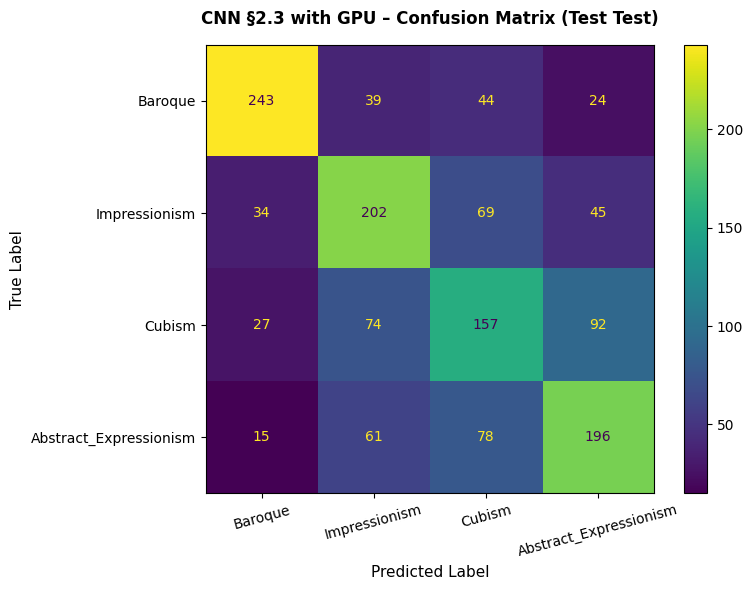

[[243  39  44  24]
 [ 34 202  69  45]
 [ 27  74 157  92]
 [ 15  61  78 196]]


In [33]:
plot_confusion_matrix(test_cm_cnn, "CNN §2.3 with GPU – Confusion Matrix (Test Test)")

**Compare the confusion matrices: in which movements does the CNN improve substantially ?**


Comparing the two above confusion matrices, the CNN improves over the FFN in all four classes. The most substantial improvement is in Impressionism: 202/350 correct vs 142/350 for the FFN (+60), suggesting that the CNN local filters better capture the patterns typical of Impressionist paintings. Baroque also improves (243/350 vs 229/350, +14), while Cubism (157/350 vs 146/350, +11) and Abstract Expressionism (196/350 vs 191/350, +5) show smaller gains. The hardest pair remains Cubism vs Abstract Expressionism, the CNN still confuses 92 Cubism samples as Abstract Expressionism and 78 Abstract Expressionism samples as Cubism, though these numbers are lower than the FFN (106 and 90). This confirms the prediction made in Q0.1 that these two classes would be the hardest to separate.

**How does the CPU-vs-GPU speedup of the CNN compare to that of the FFN, and why?**

The CNN (§2.3) has a much larger GPU speedup than the FFN: 243.0s/26.4s = 9.2x for the CNN vs 51.8s/14.8s = 3.5x for the FFN. This is because CNN operations (convolutions) are highly parallelizable i.e. the same 5×5 filter slides across thousands of positions simultaneously on the GPU, while on the CPU this is done sequentially. The FFN on the other hand uses
nn.Linear layers which are matrix multiplications, these are also parallelizable on the GPU. But because the FFN has far fewer parameters (397604 compared to 1066308 for the CNN) and simpler operations, so there is less work to parallelize, which is why the GPU advantage is smaller compared to the CNN which benefits much more from GPU acceleration.


## Sub-question Q2.3

Based on the measured times (for FFN: GPU 14.8s, CPU 51.8s and for CNN
§2.3: GPU 26.4s, CPU 243.0s, all for 30 epochs) and the train-val behavior observed (both FFN and CNN §2.3 show overfitting, train loss decreases while val loss remains higher), deepening the network to 10 convolutional layers from 4 convolutional layers for a +2% accuracy gain but with multiple times the computational cost is not always a reasonable choice.

**When it is reasonable:** <br>
Batch processing of the full 2,000,000 artworks collection where time is not critical and a GPU is available. In this case the extra computational cost is acceptable since the classification runs once and the +2% improvement means ~40,000 more correctly classified works out of 2,000,000.

**When it is not reasonable:**
- **Real time classification**: if the museum specialists need in reasonable time results when uploading a new artwork, a deeper network whose computational cost is multiple times that of §2.3 (already 26.4s for 30 epochs on GPU) would introduce too much waiting time.


- **CPU only deployment**: our §2.3 already takes 243.0s on CPU for 30 epochs for 4 convolutional layers on 3,200 training images. A 10 layer network classifying 2,000,000 artworks would multiply this cost significantly, making CPU deployment costly.


- **Reliability**: our train-val behavior already shows signs of overfitting (train loss dropping while val loss rises) with 4 layers and
3,200 training images. Because the museum has 2,000,000 artworks which is significantly more than our 3,200 training images, increasing the depth from 4 to 10 layers increases the model complexity significantly, which would likely still lead to overfitting, making it harder for museum specialists to trust the model's decisions.

## 3. Performance Improvement


### 3.1 Reproducibility, Optimizers, LR Schedule, BatchNorm

In [34]:
print("Run 1: cnn with padding, pooling and ReLU on GPU")
model_repro_1, history_repro_1, _, _ = train_cnn_on_device(cnn_pad_pool_relu, "cuda", epochs=30)

print("Run 2: cnn with padding, pooling and ReLU on GPU")
model_repro_2, history_repro_2, _, _ = train_cnn_on_device(cnn_pad_pool_relu, "cuda", epochs=30)

# Check 1: Train losses identical for the 2 runs across all epochs
losses_match = all(
    abs(l1 - l2) < 1e-6
    for l1, l2 in zip(history_repro_1["train_loss"], history_repro_2["train_loss"])
)
print(f"\nTrain losses identical for the 2 runs across all epochs: {losses_match}")
print(f"Run 1 train losses (every 5 epochs): {[round(x,4) for x in history_repro_1['train_loss'][4::5]]}")
print(f"Run 2 train losses (every 5 epochs): {[round(x,4) for x in history_repro_2['train_loss'][4::5]]}")
print("\n\n")

# Check 2: Test set performance identical for the 2 runs
criterion = nn.CrossEntropyLoss()
device = torch.device("cuda")
_, _, test_f1_1, _ = evaluate(model_repro_1, test_loader, criterion, device)
_, _, test_f1_2, _ = evaluate(model_repro_2, test_loader, criterion, device)

print(f"Run 1 – Test F1 macro = {test_f1_1:.4f}")
print(f"Run 2 – Test F1 macro = {test_f1_2:.4f}")
print(f"Test F1 macro identical for the 2 runs: {abs(test_f1_1 - test_f1_2) < 1e-6}")

Run 1: cnn with padding, pooling and ReLU on GPU
Epoch =  5 | train_loss = 1.1953 | val_loss = 1.2595 | val_F1 = 0.3566
Epoch = 10 | train_loss = 0.9844 | val_loss = 1.1500 | val_F1 = 0.4068
Epoch = 15 | train_loss = 0.7013 | val_loss = 1.1335 | val_F1 = 0.5446
Epoch = 20 | train_loss = 0.3389 | val_loss = 1.6580 | val_F1 = 0.5814
Epoch = 25 | train_loss = 0.1645 | val_loss = 2.2109 | val_F1 = 0.5493
Epoch = 30 | train_loss = 0.1129 | val_loss = 2.4957 | val_F1 = 0.5666

Device = cuda | Training time: 31.8s  |  Best epoch: 22  |  Best val F1: 0.5863


Run 2: cnn with padding, pooling and ReLU on GPU
Epoch =  5 | train_loss = 1.1953 | val_loss = 1.2595 | val_F1 = 0.3566
Epoch = 10 | train_loss = 0.9844 | val_loss = 1.1500 | val_F1 = 0.4068
Epoch = 15 | train_loss = 0.7013 | val_loss = 1.1335 | val_F1 = 0.5446
Epoch = 20 | train_loss = 0.3389 | val_loss = 1.6580 | val_F1 = 0.5814
Epoch = 25 | train_loss = 0.1645 | val_loss = 2.2109 | val_F1 = 0.5493
Epoch = 30 | train_loss = 0.1129 | val

###**Optimizer Section**

In [35]:
# Trains cnn with padding, pooling and ReLU on GPU with the given optimizer for a given number of epochs
# optimizer_name: the name of the optimizer to use i.e. SGD, SGD_momentum, Adam, RMSprop, AdamW
# lr: learning rate, weight_decay: L2 regularization strength (0 means no weight decay)
def train_with_optimizer(optimizer_name, lr, weight_decay=0, epochs=30, seed=SEED):

    device = torch.device("cuda")

    # Re-seed so each optimizer starts from the same random state.
    # Without re-seeding, the next optimizer run would start from a different
    # random state because the previous GPU run changed the random state.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    model = cnn_pad_pool_relu().to(device)
    criterion = nn.CrossEntropyLoss()

    if optimizer_name == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    elif optimizer_name == "SGD_momentum":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    elif optimizer_name == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    elif optimizer_name == "RMSprop":
        optimizer = torch.optim.RMSprop(model.parameters(), lr=lr)
    elif optimizer_name == "AdamW":
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_f1 = -1.0
    best_state = None
    best_epoch = 0

    train_history = {"train_loss": [], "val_loss": [], "val_f1": [], "val_acc": []}

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc, val_f1, _ = evaluate(model, val_loader, criterion, device)

        train_history["train_loss"].append(train_loss)
        train_history["val_loss"].append(val_loss)
        train_history["val_f1"].append(val_f1)
        train_history["val_acc"].append(val_acc)

        if val_f1 > best_f1:

            best_f1 = val_f1

            # We found a better val F1, so we save the model weights at this moment.
            # model.state_dict() is a dictionary that contains all the learned weights
            # and biases of the model from all layers.
            # Since training continues and the next epoch will overwrite these weights,
            # we use copy.deepcopy() to take a frozen snapshot of them right now
            # and store it in best_state
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if epoch % 5 == 0:
            print(f"Epoch {epoch:2d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_F1={val_f1:.4f}")

    end_time = time.time() - start_time
    print(f"\nOptimizer: {optimizer_name} | Training time: {end_time:.1f}s | Best epoch: {best_epoch} | Best val F1: {best_f1:.4f}\n")

    # Restore best model weights before returning
    model.load_state_dict(best_state)

    return model, train_history, best_epoch, train_history["val_acc"][best_epoch-1], end_time

In [36]:
# 5 optimizers to compare against the Adam baseline from §2.3
optimizer_configs = [
    ("SGD", 0.01,  0),
    ("SGD_momentum", 0.01,  0),
    ("Adam", 0.001, 0),
    ("RMSprop", 0.001, 0),
    ("AdamW", 0.001, 0.01),
]

optimizer_results = {}

for name, lr, wd in optimizer_configs:
    print(f"{'='*55}")
    print(f"Optimizer: {name}  lr={lr}  weight_decay={wd}")
    print(f"{'='*55}")
    model, train_history, best_epoch, val_acc, training_time = train_with_optimizer(name, lr, wd)
    _, test_acc, test_f1, _ = evaluate(model, test_loader, criterion, torch.device("cuda"))
    optimizer_results[name] = {
        "model": model,
        "train_history": train_history,
        "best_epoch": best_epoch,
        "val_acc": val_acc,
        "test_acc": test_acc,
        "test_f1": test_f1,
        "training_time": training_time,
    }

Optimizer: SGD  lr=0.01  weight_decay=0
Epoch  5 | train_loss=1.3866 | val_loss=1.3863 | val_F1=0.1000
Epoch 10 | train_loss=1.3865 | val_loss=1.3862 | val_F1=0.1000
Epoch 15 | train_loss=1.3864 | val_loss=1.3861 | val_F1=0.1000
Epoch 20 | train_loss=1.3863 | val_loss=1.3860 | val_F1=0.1000
Epoch 25 | train_loss=1.3860 | val_loss=1.3858 | val_F1=0.2747
Epoch 30 | train_loss=1.3855 | val_loss=1.3853 | val_F1=0.1644

Optimizer: SGD | Training time: 24.4s | Best epoch: 25 | Best val F1: 0.2747

Optimizer: SGD_momentum  lr=0.01  weight_decay=0
Epoch  5 | train_loss=1.3881 | val_loss=1.3861 | val_F1=0.1000
Epoch 10 | train_loss=1.2529 | val_loss=1.3466 | val_F1=0.2240
Epoch 15 | train_loss=1.1505 | val_loss=1.1706 | val_F1=0.4456
Epoch 20 | train_loss=0.9790 | val_loss=1.1405 | val_F1=0.5055
Epoch 25 | train_loss=0.7689 | val_loss=1.0645 | val_F1=0.5818
Epoch 30 | train_loss=0.4767 | val_loss=1.3499 | val_F1=0.5616

Optimizer: SGD_momentum | Training time: 24.2s | Best epoch: 27 | Best val 

In [37]:
rows = []
for name, res in optimizer_results.items():
    rows.append({
        "Optimizer": name,
        "Val Acc": f"{res['val_acc']:.4f}",
        "Test Acc": f"{res['test_acc']:.4f}",
        "F1 macro": f"{res['test_f1']:.4f}",
        "Best epoch": res["best_epoch"],
        "Training time": f"{res['training_time']:.1f}s",
    })

df_optimizers = pd.DataFrame(rows)
display(df_optimizers.style.set_caption("Q3.1 – Optimizer Comparison (no scheduler, no BatchNorm)"))

,Optimizer,Val Acc,Test Acc,F1 macro,Best epoch,Training time
0,SGD,0.3588,0.3414,0.2639,25,24.4s
1,SGD_momentum,0.5800,0.5779,0.5795,27,24.2s
2,Adam,0.5813,0.5700,0.5718,22,25.2s
3,RMSprop,0.6312,0.5914,0.5871,25,24.8s
4,AdamW,0.6225,0.5957,0.5876,17,25.7s


###**CosineAnnealingLR Scheduler Section**

In [38]:
# Trains cnn with padding, pooling and ReLU on GPU with the best optimizer (AdamW) + CosineAnnealingLR scheduler
def train_with_scheduler(epochs=30, seed=SEED):

    device = torch.device("cuda")

    # Re-seed so the scheduler model starts from the same random state as the other models.
    # Without re-seeding, this run would start from a different random state
    # because the previous GPU run changed the random state.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    model = cnn_pad_pool_relu().to(device)
    criterion = nn.CrossEntropyLoss()

    # Best optimizer from the comparison above
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)

    # CosineAnnealingLR: starts at lr=0.001, smoothly decays to ~0 by epoch T_max
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_f1 = -1.0
    best_state = None
    best_epoch = 0

    train_history = {"train_loss": [], "val_loss": [], "val_f1": []}

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc, val_f1, _ = evaluate(model, val_loader, criterion, device)

        # update LR after each epoch
        scheduler.step()

        train_history["train_loss"].append(train_loss)
        train_history["val_loss"].append(val_loss)
        train_history["val_f1"].append(val_f1)

        if val_f1 > best_f1:

            best_f1 = val_f1

            # We found a better val F1, so we save the model weights at this moment.
            # model.state_dict() is a dictionary that contains all the learned weights
            # and biases of the model from all layers.
            # Since training continues and the next epoch will overwrite these weights,
            # we use copy.deepcopy() to take a frozen snapshot of them right now
            # and store it in best_state
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if epoch % 5 == 0:
            print(f"Epoch {epoch:2d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_F1={val_f1:.4f}")

    end_time = time.time() - start_time
    print(f"Training time: {end_time:.1f}s | Best epoch={best_epoch} | Best val F1={best_f1:.4f}")

    # Restore best model weights before returning
    model.load_state_dict(best_state)

    return model, train_history, best_epoch, end_time

In [39]:
print("cnn with padding, pooling and ReLU on GPU with AdamW WITHOUT CosineAnnealingLR scheduler (from optimizer_results)")
print(f"Test F1 = {optimizer_results['AdamW']['test_f1']:.4f}  |  Best epoch = {optimizer_results['AdamW']['best_epoch']}  |  Training time = {optimizer_results['AdamW']['training_time']:.1f}s")

print("\ncnn with padding, pooling and ReLU on GPU with AdamW WITH CosineAnnealingLR scheduler")
model_scheduler, history_scheduler, best_epoch_scheduler, time_scheduler = train_with_scheduler(epochs=30)
_, test_acc_scheduler, test_f1_scheduler, _ = evaluate(model_scheduler, test_loader, criterion, torch.device("cuda"))
print(f"Test F1 = {test_f1_scheduler:.4f}  |  Best epoch = {best_epoch_scheduler}  |  Training time = {time_scheduler:.1f}s")

print(f"\n\nTest F1 AdamW WITH scheduler - Test F1 AdamW WITHOUT scheduler = {test_f1_scheduler - optimizer_results['AdamW']['test_f1']:.4f}")

cnn with padding, pooling and ReLU on GPU with AdamW WITHOUT CosineAnnealingLR scheduler (from optimizer_results)
Test F1 = 0.5876  |  Best epoch = 17  |  Training time = 25.7s

cnn with padding, pooling and ReLU on GPU with AdamW WITH CosineAnnealingLR scheduler
Epoch  5 | train_loss=1.1451 | val_loss=1.1151 | val_F1=0.4745
Epoch 10 | train_loss=0.8547 | val_loss=1.1968 | val_F1=0.4859
Epoch 15 | train_loss=0.4894 | val_loss=1.1462 | val_F1=0.6019
Epoch 20 | train_loss=0.1337 | val_loss=2.1576 | val_F1=0.6044
Epoch 25 | train_loss=0.0371 | val_loss=2.6827 | val_F1=0.6089
Epoch 30 | train_loss=0.0213 | val_loss=2.8752 | val_F1=0.6063
Training time: 25.4s | Best epoch=21 | Best val F1=0.6233
Test F1 = 0.5785  |  Best epoch = 21  |  Training time = 25.4s


Test F1 AdamW WITH scheduler - Test F1 AdamW WITHOUT scheduler = -0.0091


###**BatchNorm Section**

In [40]:
class cnn_pad_pool_relu_batchnorm(nn.Module):

    # Constructor
    def __init__(self):

        # Calls the Constructor of the parent class i.e. nn.Module
        super().__init__()

        # identical to cnn_pad_pool_relu class but with nn.BatchNorm2d added before each ReLU
        # in the conv layers. BatchNorm2d normalizes the output of each conv layer per batch
        # and then applies learnable scale and shift parameters, this stabilizes training
        # and allows the network to learn faster and more reliably

        #   original image: 32 * 32 * 3 (3 RGB channels)
        #   after conv1: 32 * 32 * 16  (with padding = 2 preserves size, we gain 16 feature maps)
        #   after bn1:   32 * 32 * 16  (BatchNorm does not change size)
        #   after relu1: 32 * 32 * 16  (ReLU does not change size, only zeroes negatives)
        #   after pool1: 16 * 16 * 16  (MaxPool halves the size)
        #   after conv2: 16 * 16 * 32  (with padding = 2 preserves size, we gain 32 feature maps)
        #   after bn2:   16 * 16 * 32  (BatchNorm does not change size)
        #   after relu2: 16 * 16 * 32  (ReLU does not change size, only zeroes negatives)
        #   after pool2: 8 *  8 * 32   (MaxPool halves the size)
        #   after conv3: 8 *  8 * 64   (with padding = 2 preserves size, we gain 64 feature maps)
        #   after bn3:   8 *  8 * 64   (BatchNorm does not change size)
        #   after relu3: 8 *  8 * 64   (ReLU does not change size, only zeroes negatives)
        #   after pool3: 4 *  4 * 64   (MaxPool halves the size)
        #   after conv4: 4 * 4 * 128   (with padding = 2 preserves size, we gain 128 feature maps)
        #   after bn4:   4 * 4 * 128   (BatchNorm does not change size)
        #   after relu4: 4 * 4 * 128   (ReLU does not change size, only zeroes negatives)
        #   after pool4: 2 *  2 * 128  (MaxPool halves the size)

        # So in self.features we extract features
        # filter = the 5 * 5 sliding window that slides across the image (the tool)
        # feature = the output of applying a filter to the image (the result)

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=5, padding=2),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        # x is the flattened output of the last stage: 2 * 2 (image size) * 128 (feature maps)
        x = 128 * 2 * 2

        # classifier: same structure as in cnn_pad_pool_relu class but without BatchNorm
        # since the assignment only asks for BatchNorm in the conv layers
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.ReLU(),
            nn.Linear(x, 1024),
            nn.ReLU(),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Linear(32, 4),
        )

    # x is a batch of images with shape [batch_size, 3, 32, 32]
    # forward passes x through:
    #   1. self.features   (conv layers)   -> extracts features from the image
    #   2. self.classifier (linear layers) -> downgrades features to 4 class scores (Baroque, Impressionism, Cubism, Abstract Expressionism)
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [41]:
# Trains cnn with padding, pooling and ReLU, BatchNorm on GPU with the best optimizer (AdamW) + CosineAnnealingLR scheduler
def train_with_batchnorm(epochs=30, seed=SEED):

    device = torch.device("cuda")

    # Re-seed so the batchnorm model starts from the same random state as the other models.
    # Without re-seeding, this run would start from a different random state
    # because the previous GPU run changed the random state.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    model = cnn_pad_pool_relu_batchnorm().to(device)
    criterion = nn.CrossEntropyLoss()

    # Best optimizer (from the comparison above) + scheduler
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_f1 = -1.0
    best_state = None
    best_epoch = 0

    train_history = {"train_loss": [], "val_loss": [], "val_f1": []}

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
        val_loss, val_acc, val_f1, _ = evaluate(model, val_loader, criterion, device)

        # update LR after each epoch
        scheduler.step()

        train_history["train_loss"].append(train_loss)
        train_history["val_loss"].append(val_loss)
        train_history["val_f1"].append(val_f1)

        if val_f1 > best_f1:

            best_f1 = val_f1

            # We found a better val F1, so we save the model weights at this moment.
            # model.state_dict() is a dictionary that contains all the learned weights
            # and biases of the model from all layers.
            # Since training continues and the next epoch will overwrite these weights,
            # we use copy.deepcopy() to take a frozen snapshot of them right now
            # and store it in best_state
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if epoch % 5 == 0:
            print(f"Epoch {epoch:2d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_F1={val_f1:.4f}")

    end_time = time.time() - start_time
    print(f"Training time: {end_time:.1f}s | Best epoch={best_epoch} | Best val F1={best_f1:.4f}")

    # Restore best model weights before returning
    model.load_state_dict(best_state)

    return model, train_history, best_epoch, end_time

In [42]:
print("cnn with padding, pooling, ReLU and BatchNorm on GPU with Optimizer AdamW + CosineAnnealingLR scheduler")
model_bn, history_bn, best_epoch_bn, time_bn = train_with_batchnorm(epochs=30)
_, test_acc_bn, test_f1_bn, _ = evaluate(model_bn, test_loader, criterion, torch.device("cuda"))
print(f"Test F1 = {test_f1_bn:.4f}  |  Best epoch = {best_epoch_bn}  |  Training time = {time_bn:.1f}s")

cnn with padding, pooling, ReLU and BatchNorm on GPU with Optimizer AdamW + CosineAnnealingLR scheduler
Epoch  5 | train_loss=0.9550 | val_loss=2.0566 | val_F1=0.3945
Epoch 10 | train_loss=0.6973 | val_loss=0.8944 | val_F1=0.6386
Epoch 15 | train_loss=0.4210 | val_loss=0.9684 | val_F1=0.6247
Epoch 20 | train_loss=0.1316 | val_loss=1.4616 | val_F1=0.6330
Epoch 25 | train_loss=0.0361 | val_loss=1.8332 | val_F1=0.6470
Epoch 30 | train_loss=0.0238 | val_loss=1.9986 | val_F1=0.6409
Training time: 29.1s | Best epoch=14 | Best val F1=0.6635
Test F1 = 0.6355  |  Best epoch = 14  |  Training time = 29.1s


In [43]:
df_optimizers = pd.DataFrame(rows)
display(df_optimizers.style.set_caption("Q3.1 – Optimizer Comparison (no scheduler, no BatchNorm)"))

,Optimizer,Val Acc,Test Acc,F1 macro,Best epoch,Training time
0,SGD,0.3588,0.3414,0.2639,25,24.4s
1,SGD_momentum,0.5800,0.5779,0.5795,27,24.2s
2,Adam,0.5813,0.5700,0.5718,22,25.2s
3,RMSprop,0.6312,0.5914,0.5871,25,24.8s
4,AdamW,0.6225,0.5957,0.5876,17,25.7s


## Sub-question Q3.1

**Which optimizer prevailed in performance and convergence speed (best epoch) ?**

AdamW achieved the best test F1 macro (0.5876) and found its best model the earliest at epoch 17, outperforming all other optimizers on both criteria.

- RMSprop followed closely in performance (test F1 macro = 0.5871) but found its best model much later at epoch 25

- Adam found its best model at epoch 22 with test F1 macro = 0.5718

- SGD with momentum found its best model at epoch 27 with test F1 macro = 0.5795

- SGD without momentum performed by far the worst (test F1 macro = 0.2639, best epoch = 25), barely learning anything across 30 epochs, showing how critical momentum is for SGD to work effectively

<br>

**Discuss the observed difference between SGD and adaptive optimizers (Adam, RMSprop, AdamW):**

The difference is dramatic. Plain SGD with lr = 0.01 essentially failed to converge, stuck near random performance (test F1 macro = 0.2639). This happens because SGD uses the same fixed learning rate for all parameters in the network regardless of whether that parameter needs a big or small update, making it very sensitive to the choice of lr i.e. too large causes oscillations, too small causes extremely slow progress.

The adaptive optimizers (Adam, RMSprop, AdamW) all performed significantly better than plain SGD, achieving test F1 macro scores of 0.5718, 0.5871, and 0.5876 respectively, while SGD with momentum also outperformed plain SGD with test F1 macro = 0.5795. For SGD with momentum the improvement over plain SGD is because momentum accumulates gradients in consistent directions helping escape flat regions. For the adaptive optimizers (Adam, RMSprop, AdamW) the reason they performed better than plain SGD is because they automatically adjust the learning rate per parameter based on past gradients i.e. parameters that receive large gradients get smaller updates and vice versa, allowing faster and more stable convergence without requiring careful manual lr tuning.

<br>

**How did the cosine LR schedule affect training ?**

Adding CosineAnnealingLR to AdamW slightly worsened the test F1 macro
(0.5785 vs 0.5876, a difference of -0.0091), even though the best val F1 improved (0.6233 vs 0.6179). The scheduler pushed the train loss much lower (0.0213 at epoch 30 vs 0.1233 without scheduler), indicating more aggressive overfitting, and the best model was found later at epoch 21 instead of epoch 17, suggesting the scheduler slowed down convergence slightly. These results make sense because CosineAnnealingLR gradually reduces the learning rate to ~0 by epoch 30, allowing the model to fit the training data very tightly in the final epochs. This explains why the best model was found later (epoch 21 vs 17) and why the val F1 improved (0.6233 vs 0.6179) while the test F1 slightly worsened (0.5785 vs 0.5876), as the model overfit more to the training and validation distribution but generalized slightly less well to the unseen test set.

<br>

**How did the addition of BatchNorm affect training ?**

Adding BatchNorm (with AdamW + CosineAnnealingLR) significantly improved
performance the test F1 macro jumped to 0.6355 from 0.5785 (with scheduler alone), an improvement of +0.0570 and the best model was found much earlier at epoch 14 instead of epoch 21. These results make sense because BatchNorm acts as a regularizer as a side effect of its normalization process, it normalizes the output of each conv layer per batch and applies learnable scale and shift parameters, and since the normalization statistics change with each batch, it stabilizes the training and allows gradients to flow more smoothly through the network. This means that at each layer the inputs are always in a well scaled range, so the optimizer does not waste early epochs struggling with poorly scaled activations, allowing it to converge faster and reach a better solution. This is why the best model is found earlier (epoch 14 vs 21), as the model reaches a better generalization point sooner before overfitting kicks in, leading to better performance on the unseen test set.

<br>

**Intuitively describe what a LR schedule does during training**

A LR schedule automatically changes the learning rate as training progresses. At the beginning of training a high learning rate allows the model to make large steps and move quickly toward a good solution, learning the most important patterns fast. As training continues the learning rate is gradually reduced, allowing the model to make smaller and more precise adjustments to fine-tune the weights and settle into a good optimal point without overshooting it. Without a schedule the learning rate stays fixed, which means it may be too large in the later epochs causing the model to keep overshooting the optimal weights. The CosineAnnealingLR specifically follows a smooth cosine curve, starting at lr = 0.001 (large steps, fast learning) and decreasing to ~0 by epoch T_max = 30 (very small steps, fine-tuning). This is exactly what we observed, in the early epochs the model learned quickly, while in the final epochs the very low learning rate allowed the model to fit the training data very tightly, causing the train loss to drop aggressively to 0.0213 by epoch 30, which indicates overfitting rather than precise generalization.

### 3.2 Data augmentation and regularization

In [44]:
import torchvision.transforms as transforms
from torch.utils.data import Dataset, TensorDataset, DataLoader

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(32, padding=4),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
])

# Custom Dataset that applies augmentation transforms on the fly during training
# This means each epoch the same image is seen with a different random augmentation
class AugmentedDataset(Dataset):

    # Constructor
    def __init__(self, X, y, transform=None):
        self.X = X
        self.y = y
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):

        # Each image is a [3, 32, 32] float tensor in [0, 1]
        img = self.X[idx]

        if self.transform:
            img = self.transform(img)

        return img, self.y[idx]

# Plain training dataset (no augmentation) used for baseline and regularization only configs
train_dataset_plain = TensorDataset(X_train, y_train)

# Augmented training dataset used for augmentation and augmentation + regularization configs
train_dataset_aug = AugmentedDataset(X_train, y_train, transform=train_transform)

train_loader_plain = DataLoader(train_dataset_plain, batch_size=16, shuffle=True)
train_loader_aug = DataLoader(train_dataset_aug, batch_size=16, shuffle=True)

In [45]:
class cnn_batchnorm_dropout(nn.Module):

    # Constructor
    # dropout_p: dropout probability (0.0 = no dropout, 0.3 = regularization)
    def __init__(self, dropout_p=0.0):

        # Calls the Constructor of the parent class i.e. nn.Module
        super().__init__()

        # identical to cnn_pad_pool_relu_batchnorm class but with
        # Dropout(p=dropout_p) added before each Linear layer in self.classifier

        #   original image: 32 * 32 * 3 (3 RGB channels)
        #   after conv1: 32 * 32 * 16  (with padding = 2 preserves size, we gain 16 feature maps)
        #   after bn1:   32 * 32 * 16  (BatchNorm does not change size)
        #   after relu1: 32 * 32 * 16  (ReLU does not change size, only zeroes negatives)
        #   after pool1: 16 * 16 * 16  (MaxPool halves the size)
        #   after conv2: 16 * 16 * 32  (with padding = 2 preserves size, we gain 32 feature maps)
        #   after bn2:   16 * 16 * 32  (BatchNorm does not change size)
        #   after relu2: 16 * 16 * 32  (ReLU does not change size, only zeroes negatives)
        #   after pool2: 8 *  8 * 32   (MaxPool halves the size)
        #   after conv3: 8 *  8 * 64   (with padding = 2 preserves size, we gain 64 feature maps)
        #   after bn3:   8 *  8 * 64   (BatchNorm does not change size)
        #   after relu3: 8 *  8 * 64   (ReLU does not change size, only zeroes negatives)
        #   after pool3: 4 *  4 * 64   (MaxPool halves the size)
        #   after conv4: 4 *  4 * 128  (with padding = 2 preserves size, we gain 128 feature maps)
        #   after bn4:   4 *  4 * 128  (BatchNorm does not change size)
        #   after relu4: 4 *  4 * 128  (ReLU does not change size, only zeroes negatives)
        #   after pool4: 2 *  2 * 128  (MaxPool halves the size)

        # So in self.features we extract features
        # filter = the 5 * 5 sliding window that slides across the image (the tool)
        # feature = the output of applying a filter to the image (the result)

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=5, padding=2),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(16, 32, kernel_size=5, padding=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(32, 64, kernel_size=5, padding=2),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Conv2d(64, 128, kernel_size=5, padding=2),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        # x is the flattened output of the last stage: 2 * 2 (image size) * 128 (feature maps)
        x = 128 * 2 * 2

        # classifier: same structure as in cnn_pad_pool_relu_batchnorm class
        # but with Dropout(p=dropout_p) added before each Linear layer
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout_p),
            nn.Linear(x, 1024),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(256, 32),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(32, 4),
        )

    # x is a batch of images with shape [batch_size, 3, 32, 32]
    # forward passes x through:
    #   1. self.features   (conv layers)   -> extracts features from the image
    #   2. self.classifier (linear layers) -> downgrades features to 4 class scores (Baroque, Impressionism, Cubism, Abstract Expressionism)
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [46]:
# Trains cnn_batchnorm_dropout on GPU with AdamW + CosineAnnealingLR for 60 epochs
# with optional data augmentation, dropout and weight decay
def train_with_augmentation_regularization(config_name, dropout_p, weight_decay, use_aug, epochs=60, seed=SEED):

    device = torch.device("cuda")

    # Re-seed so each configuration starts from the same random state
    # Without re-seeding, the next configuration run would start from a different
    # random state because the previous run changed the random state
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

    model = cnn_batchnorm_dropout(dropout_p=dropout_p).to(device)
    criterion = nn.CrossEntropyLoss()

    # Best optimizer (AdamW) with optional weight_decay for regularization
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    # Choose the right DataLoader based on whether augmentation is enabled
    if use_aug:
      loader = train_loader_aug
    else:
      loader = train_loader_plain

    best_f1 = -1.0
    best_state = None
    best_epoch = 0

    train_history = {"train_loss": [], "val_loss": [], "val_f1": []}

    start_time = time.time()

    for epoch in range(1, epochs + 1):

        train_loss = train_one_epoch(model, loader, optimizer, criterion, device)
        val_loss, val_acc, val_f1, _ = evaluate(model, val_loader, criterion, device)

        # Update LR after each epoch
        scheduler.step()

        train_history["train_loss"].append(train_loss)
        train_history["val_loss"].append(val_loss)
        train_history["val_f1"].append(val_f1)

        if val_f1 > best_f1:

            best_f1 = val_f1

            # We found a better val F1, so we save the model weights at this moment.
            # model.state_dict() is a dictionary that contains all the learned weights
            # and biases of the model from all layers.
            # Since training continues and the next epoch will overwrite these weights,
            # we use copy.deepcopy() to take a frozen snapshot of them right now
            # and store it in best_state
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch

        if epoch % 5 == 0:
            print(f"Epoch {epoch:2d} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | val_F1={val_f1:.4f}")

    end_time = time.time() - start_time
    print(f"\nConfiguration: {config_name} | Training time: {end_time:.1f}s | Best epoch: {best_epoch} | Best val F1: {best_f1:.4f}\n")

    # Restore best model weights before returning
    model.load_state_dict(best_state)

    return model, train_history, best_epoch, end_time

In [47]:
# 4 configurations
# each configuration adds one component on top of the
# cnn_pad_pool_relu_batchnorm + AdamW + CosineAnnealingLR now trained for 60 epochs
experiments = {
    "No regularization" : {"dropout_p": 0.0, "weight_decay": 0, "use_aug": False},
    "Augmentation only" : {"dropout_p": 0.0, "weight_decay": 0, "use_aug": True},
    "Regularization only" : {"dropout_p": 0.3, "weight_decay": 1e-4, "use_aug": False},
    "Augmentation + Regularization": {"dropout_p": 0.3, "weight_decay": 1e-4, "use_aug": True},
}

results_augmentation_regularization = {}
criterion_augmentation_regularization = nn.CrossEntropyLoss()

for config_name, params in experiments.items():
    print(f"{'='*55}")
    print(f"Training: {config_name}")
    print(f"{'='*55}")

    model, history, best_epoch, end_time = train_with_augmentation_regularization(config_name, epochs=60, **params)

    _, val_acc, val_f1,  _ = evaluate(model, val_loader,  criterion_augmentation_regularization, torch.device("cuda"))
    _, test_acc, test_f1, _ = evaluate(model, test_loader, criterion_augmentation_regularization, torch.device("cuda"))

    # Train val gap at best epoch, positive means val_loss > train_loss (overfitting)
    train_val_gap = history["val_loss"][best_epoch - 1] - history["train_loss"][best_epoch - 1]

    results_augmentation_regularization[config_name] = {
        "history" : history,
        "best_epoch" : best_epoch,
        "val_f1" : val_f1,
        "test_f1" : test_f1,
        "train_val_gap" : train_val_gap,
        "training_time" : end_time
    }

    print(f"Best model at epoch = {best_epoch} with: Val F1 = {val_f1:.4f} | Test F1 = {test_f1:.4f} | Train-Val gap = {train_val_gap:.4f}\n")

Training: No regularization
Epoch  5 | train_loss=0.9456 | val_loss=0.9859 | val_F1=0.5722
Epoch 10 | train_loss=0.7109 | val_loss=1.0340 | val_F1=0.5453
Epoch 15 | train_loss=0.4790 | val_loss=0.9407 | val_F1=0.6492
Epoch 20 | train_loss=0.2247 | val_loss=1.4753 | val_F1=0.6117
Epoch 25 | train_loss=0.1062 | val_loss=1.7762 | val_F1=0.6212
Epoch 30 | train_loss=0.0833 | val_loss=1.9607 | val_F1=0.6224
Epoch 35 | train_loss=0.0298 | val_loss=2.5773 | val_F1=0.6149
Epoch 40 | train_loss=0.0105 | val_loss=2.6834 | val_F1=0.6491
Epoch 45 | train_loss=0.0132 | val_loss=2.8402 | val_F1=0.6252
Epoch 50 | train_loss=0.0043 | val_loss=2.9346 | val_F1=0.6376
Epoch 55 | train_loss=0.0020 | val_loss=3.0561 | val_F1=0.6362
Epoch 60 | train_loss=0.0015 | val_loss=3.0740 | val_F1=0.6438

Configuration: No regularization | Training time: 62.1s | Best epoch: 12 | Best val F1: 0.6519

Best model at epoch = 12 with: Val F1 = 0.6519 | Test F1 = 0.6305 | Train-Val gap = 0.2635

Training: Augmentation only

In [48]:
# Plots train and val loss curves for a given configuration
# with a vertical line marking the best epoch
def plot_loss_curves(config_name, res):
    epochs_range = range(1, 61)
    plt.figure(figsize=(7, 5))
    plt.plot(epochs_range, res["history"]["train_loss"], label="Train Loss", color="blue")
    plt.plot(epochs_range, res["history"]["val_loss"],   label="Val Loss",   color="orange")
    plt.axvline(x=res["best_epoch"], color="red", linestyle="--",
                label=f"Best epoch ({res['best_epoch']})")
    plt.title(config_name)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

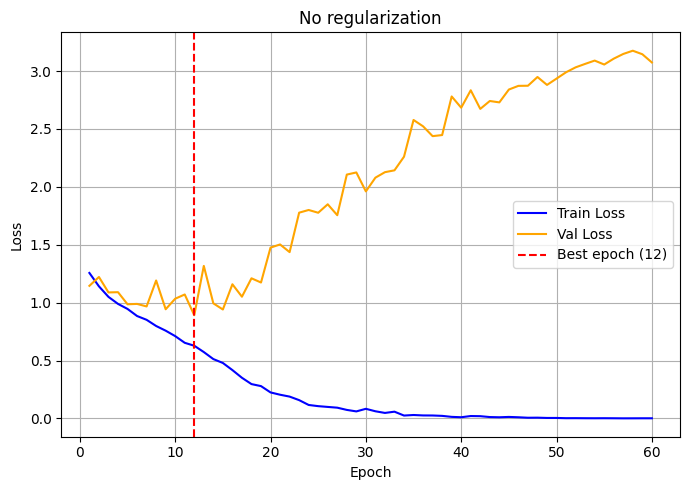

In [49]:
plot_loss_curves("No regularization", results_augmentation_regularization["No regularization"])

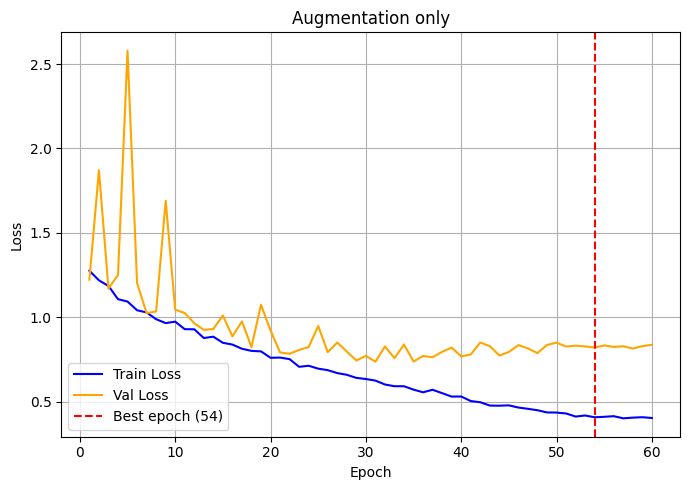

In [50]:
plot_loss_curves("Augmentation only", results_augmentation_regularization["Augmentation only"])

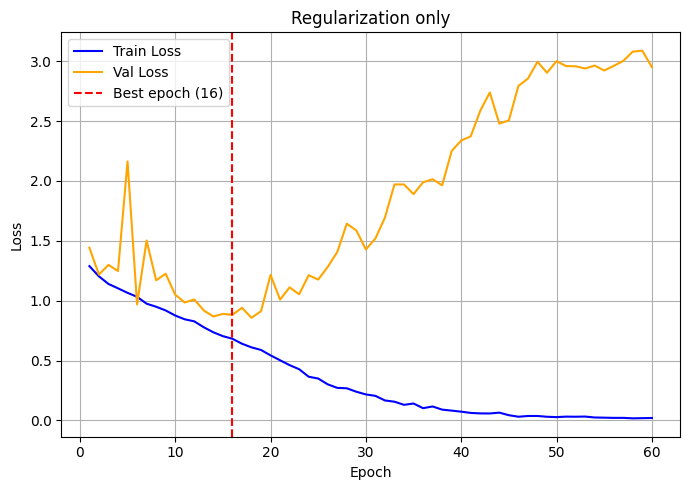

In [51]:
plot_loss_curves("Regularization only", results_augmentation_regularization["Regularization only"])

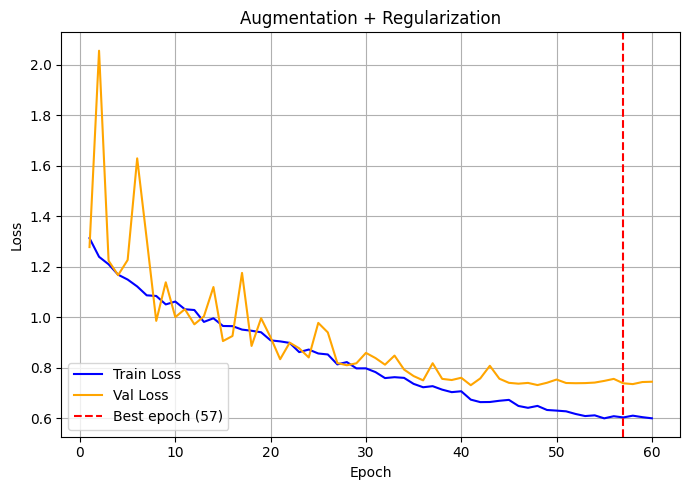

In [52]:
plot_loss_curves("Augmentation + Regularization", results_augmentation_regularization["Augmentation + Regularization"])

In [53]:
rows_augmentation_regularization = []
for config_name, res in results_augmentation_regularization.items():
    rows_augmentation_regularization.append({
        "Configuration" : config_name,
        "Best epoch" : res["best_epoch"],
        "Val F1" : f"{res['val_f1']:.4f}",
        "Test F1" : f"{res['test_f1']:.4f}",
        "Train-Val gap" : f"{res['train_val_gap']:.4f}",
        "Training time" : f"{res['training_time']:.1f}s"
    })

df_augmentation_regularization = pd.DataFrame(rows_augmentation_regularization)
display(df_augmentation_regularization.style.set_caption("Q3.2 – Augmentation and Regularization Comparison"))

,Configuration,Best epoch,Val F1,Test F1,Train-Val gap,Training time
0,No regularization,12,0.6519,0.6305,0.2635,62.1s
1,Augmentation only,54,0.7223,0.7024,0.4130,168.1s
2,Regularization only,16,0.6817,0.6403,0.1997,64.6s
3,Augmentation + Regularization,57,0.7316,0.6911,0.1352,168.7s


## Sub-question Q3.2

**In which configuration does the train-val gap (val_loss − train_loss) decrease the most, and in which does the test set performance increase ? Do these coincide ?**

The configuration with the smallest train-val gap is Augmentation + Regularization (0.1352), followed by Regularization only (0.1997), No regularization (0.2635) and Augmentation only (0.4130). The configuration with the best test F1 is Augmentation only (0.7024), followed by Augmentation + Regularization (0.6911), Regularization only (0.6403) and No regularization (0.6305).

These two do not coincide. The configuration with the smallest train-val gap (Augmentation + Regularization) is not the one with the best test F1 (Augmentation only). This shows that minimizing the train-val gap does not always maximize test performance.

<br>

**What do you conclude about the relationship between good generalization and absence of overfitting ?**

The results show that good generalization and absence of overfitting are related but not identical. Augmentation only has the best test F1 (0.7024) but also the largest train-val gap (0.4130), meaning it still overfits significantly. This happens because augmentation keeps the train loss high (0.4029 at epoch 60) by making training harder, so the train-val gap remains large even though the model generalizes well. Augmentation + Regularization achieves the smallest train-val gap (0.1352) by combining both techniques, but its test F1 (0.6911) is slightly lower than augmentation only, suggesting that adding dropout and weight decay on top of augmentation slightly limits the model's ability to generalize. The key conclusion is that reducing overfitting is a useful signal but not the only goal, what matters is how well the model performs on truly unseen data (test set) and augmentation alone achieves this best here by forcing the model to learn more robust features through varied training samples.

<br>

**Which transforms did you decide were wrong for paintings, and why ?**

Three transforms were excluded as semantically incorrect for paintings:

- **RandomVerticalFlip**: paintings have a fixed orientation determined by the artist. Flipping a painting vertically produces an unnatural upside down image that no longer represents a valid painting from any artistic movement, with one possible exception being Abstract Expressionism where paintings represent abstract and obscured objects or scenes with no recognizable subject matter meaning orientation matters less.

- **RandomRotation**: rotating the entire image by a random angle would tilt everything inside it, for example a standing figure in a Baroque portrait would appear diagonal or a landscape horizon in an Impressionist painting would no longer be horizontal. Unlike horizontal flipping which produces a natural looking mirrored image, rotation produces an unnatural result that no longer represents a valid painting, destroying the artist's deliberate choices about perspective, balance and subject placement.

- **Extreme ColorJitter**: applying extreme color distortion would particularly hurt Baroque and Impressionism since both have very characteristic color palettes that are key discriminating features. Baroque uses very dark tones with dramatic light-dark contrast or grey/white backgrounds in a sketch style, while Impressionism consistently shows brighter palettes of blues, greens and warm yellows. Cubism and Abstract Expressionism would be less affected since both use a wide variety of colors with different color intensities, making them less dependent on a specific color tone. However extreme color distortion would still destroy information the classifier needs to distinguish between movements, which is why we used only mild ColorJitter (brightness=0.1, contrast=0.1) to simulate different scan and lighting conditions without altering the characteristic palettes.